# Boundary/Break

In [1]:
import scala.util.boundary, boundary.break

import scala.util.boundary, boundary.break


In [2]:
type Not[A] = A => Nothing

defined type Not

* Escape channels for values of type A are _functions_ `A => Nothing`, i.e. not A. Actually, not functions, but continuations or consumers of type `A`.
* Escape channels for A can be used whenever we need a function from A to any type B.
* We can have consumers of consumers, i.e. not not A.
* When we invoke an escape channel with an A, the current computation will be aborted, i.e. the escape channel doesn't return. That's means finding a contradiction: aborting.
* A computation of type A can be finished by providing an A or by aborting.
* When we create a boundary of type A, an escape channel of type A named [`break`](https://github.com/scala/scala3/blob/3.8.2/library/src/scala/util/boundary.scala#L59) will be made available.
* If the escape channel is used, the value will be captured at the boundary level. This means the continuation is delimited.
* We can create an escape channel of type A, if I can find a way to abort the computation given an A. 

# Classical tautologies

In [3]:
trait LEM: 
    def apply[A]: A Either Not[A]

object LEM:
    given LEM with
        def apply[A]: A Either Not[A] = 
            boundary: 
                Right((a: A) => break(Left(a)))

defined trait LEM
defined object LEM

In [4]:
try
    summon[LEM].apply[Int] match 
        case Left(i) => ??? //  won't  happen
        case Right(noti) => noti(1)
catch
    case e: scala.util.boundary.Break[Either[Int, Not[Int]]] => e.value

res4: Either[Int, Not[Int]] = Left(value = 1)

If we're faced with the challenge of creating a value of type A or an escape channel of type A, we can create a boundary for the result and choose to create a consumer. Then, given an A we will use the boundary's channel to abort. 

In [5]:
trait DNE: 
    def apply[A]: Not[Not[A]] => A

object DNE:
    given DNE with
        def apply[A]: Not[Not[A]] => A = 
            nna => 
                boundary: 
                    nna(break)

defined trait DNE
defined object DNE

In this case, we are said that we can abort a computation given an escape channel for A.  This could only be done if we had internally an A, which justfies the reasoning scheme. To complete the proof, we create a boundary and pass the escape channel to nna, thus aborting the computation and completing the requirement for A indirectly.

In [6]:
summon[DNE][Int]: break => 
    break(1)

res6: Int = 1

In [7]:
trait Pierce: 
    def apply[A, B]: ((A => B) => A) => A

object Pierce:  
    given Pierce with 
        def apply[A, B]: ((A => B) => A) => A = 
            f => 
                boundary: 
                    f(break)

defined trait Pierce
defined object Pierce

In pierce, we exploit the fact that a consumer can stand by any other function, and conclude the boundary normally, i.e. without aborting (unlike in DNE). 

In [8]:
trait Clavius: 
    def apply[A]: (Not[A] => A) => A

object Clavius:  
    given Clavius with 
        def apply[A]: (Not[A] => A) => A = 
            f => 
                boundary: /* break => */
                    f(break)

defined trait Clavius
defined object Clavius

In clavius, we just pass the consumer directly to the given function, i.e. no need to fake a function A => B as in pierce.

In [9]:
summon[Clavius][Int]: break => 
    break(2)

res9: Int = 2

### Double Negation Elimination

In [9]:
def DNE_CallCC(callcc: CallCC): DNE = new DNE:
    def apply[A]: Not[Not[A]] => A = 
        (nna: Not[A] => Nothing) => 
            callcc[A, Nothing]: (k: Not[A]) => 
                nna(a => k(a)) : A

-- [E006] Not Found Error: cell10.sc:1:23 --------------------------------------
1 |def DNE_CallCC(callcc: CallCC): DNE = new DNE:
  |                       ^^^^^^
  |                       Not found: type CallCC
  |
  | longer explanation available when compiling with `-explain`
Compilation Failed

In [ ]:
def DNE_LEM(LEM: LEM): DNE = new DNE:
    def apply[A]: Not[Not[A]] => A = 
        LEM[A] match 
            case Left(a: A) => _ => a
            case Right(na: Not[A]) => _(na)

In [ ]:
def DNE_CallCC(callcc: CallCC): DNE = new DNE:
    def apply[A]: Not[Not[A]] => A = 
        callcc[A, Nothing].apply

In [10]:
def DNE_Clavius(clavius: Clavius): DNE = new DNE:
    def apply[A]: Not[Not[A]] => A = 
        clavius[A].apply

defined function DNE_Clavius

### Law of Excluded Middle (LEM)

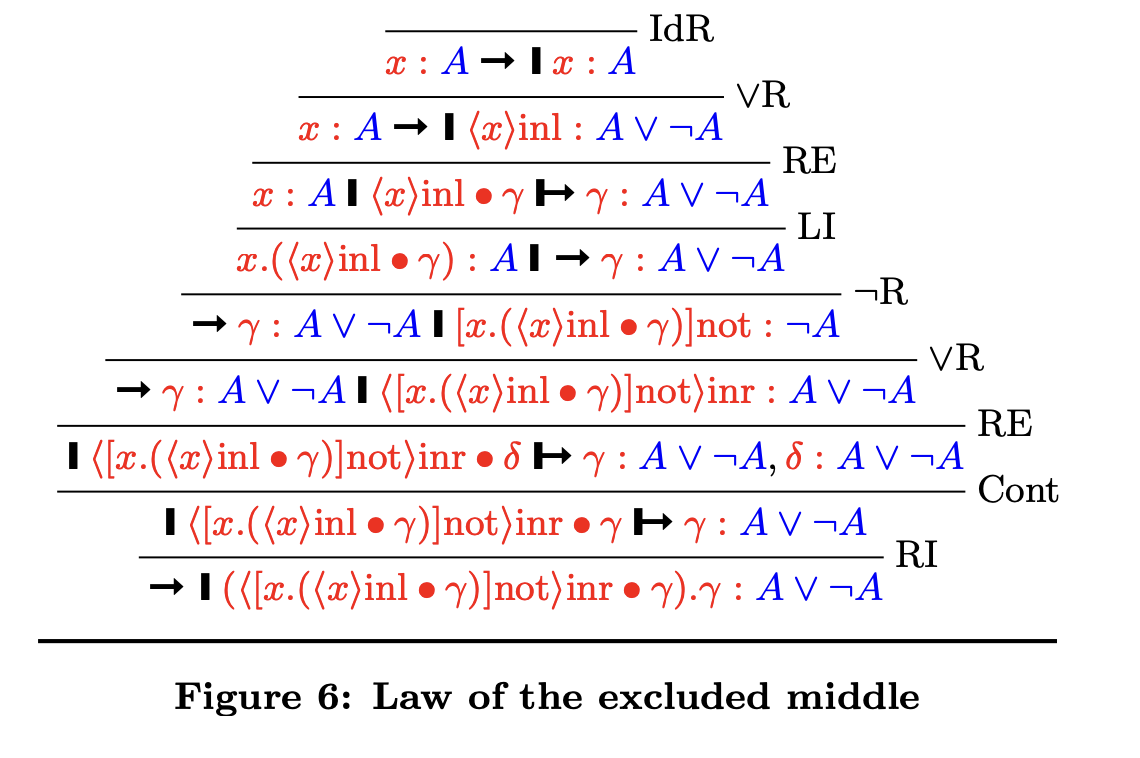

In [11]:
def LEM[A](using DNE: DNE): A Either Not[A] = 
    DNE[A Either Not[A]]: γ => 
        γ(Right(a => γ(Left(a))))

defined function LEM

Devil. I offer you A or any wish (bottom) if you give me an A

Fausto. Ok

Devil. Here it's the promise to grant you any wish if you give me an A

Fausto. Here is an A.

Devil. Change mind, I give you your A back.


In [12]:
def LEM[A](using boundary: Clavius): A Either Not[A] = 
    boundary[A Either Not[A]]: break => 
        Right(a => break(Left(a)))

defined function LEM

In [13]:
def LEM[A]: A Either Not[A] = 
    boundary:
        Right((a: A) => break(Left(a)))

defined function LEM

Let's declare an escape channel for A v not A, and choose to create an escape channel for A (i.e. not A). This means that given an A, I should be able to abort. But this I know how to do it: just abort with the given A and the available escape channel for A v not A.

### Peirce law

In [14]:
def call_cc[A, B]: ((A => B) => A) => A = 
    (f: (A => B) => A) => 
        boundary: 
            f(break)

defined function call_cc

λh . μα . [α] h(λu . [α] u)

In [39]:
def call_cc[P, Q](using μ: DNE): ((P => Q) => P) => P = 
    (h: (P => Q) => P) => 
        μ[P]: (α: Not[P]) => 
            α(h((u: P) => α(u)))

defined function call_cc

In [26]:
def call_cc[A, B]: ((A => B) => A) => A = 
    (f: (A => B) => A) => 
        f((a: A) => ??? : B)??? : A

defined function call_cc

### De Morgan

In [16]:
def proof[A, B](C: DNE): Not[(A, B)] => Not[A] Either Not[B] = 
    (f: Not[(A, B)]) => 
        C[Not[A] Either Not[B]]: k => 
            k(Left: a =>
                k(Right: b => 
                    f((a,b))))

defined function proof

In [17]:
def proof[A, B]: Not[(A, B)] => Not[A] Either Not[B] = 
    (f: Not[(A, B)]) => 
        boundary: 
            break(Left: (a: A) =>
                break(Right: (b: B) => 
                    f((a,b))))

defined function proof

In [19]:
def proof[A, B](callcc: Pierce): Not[(A, B)] => Not[A] Either Not[B] = 
    (f: Not[(A, B)]) => 
        callcc[Not[A] Either Not[B], Nothing]: break =>  
            break(Left: (a: A) =>
                break(Right: (b: B) => 
                    f((a,b))))

defined function proof

### The Łukasiewicz axiom

((p→q)→r)→(r→p)→p

In [24]:
def proof[P, Q, R]: ((P => Q) => R) => (R => P) => P = 
    (f: (P => Q) => R) => 
        (g: R => P) => 
            g(f((p: P) => ??? : Q) : R) : P

defined function proof

In [36]:
def proof[P, Q, R](using μ: DNE): ((P => Q) => R) => (R => P) => P = 
    (h: (P => Q) => R) => 
        (g: R => P) => 
            μ[P]: (k: Not[P]) => 
                k(g(h(k)))

defined function proof

### Weak LEM

In [ ]:
def proof[A](DN: DoubleNegation): Not[A] Either Not[Not[A]] = 
    DN[Not[A] Either Not[Not[A]]]: k => 
        k(Left((a: A) => k(Right(_(a)))))

In [ ]:
def proof[A](DN: DoubleNegation): Not[A] Either Not[Not[A]] = 
    boundary: 
        break(Left((a: A) => break(Right((na: Not[A]) => na(a)))))

In [ ]:
def proof[A](DN: DoubleNegation): Not[A] Either Not[Not[A]] = 
    DN[Not[A] Either Not[Not[A]]]: k => 
        k(Right(na => k(Left(na))))

### Contrapositive reversal

In [ ]:
def proof[A, B](DN: DoubleNegation): (Not[B] => Not[A]) => A => B = 
    (f: Not[B] => Not[A]) => 
        (a: A) => 
            DN[B]: k => 
                f(k)(a)

In [101]:
def proof[A, B]: (Not[B] => Not[A]) => A => B = 
    (f: Not[B] => Not[A]) => 
        (a: A) => 
            boundary[B]: 
                f(break)(a): Nothing

defined function proof

If I can transform consumers of Bs into consumers of As, then I can transform As into Bs. 

Given the transformer of consumers, and a value of type A, then, I can create a boundary of Bs which will make available a consumer of Bs. But then, I can obtain a consumer of As, and escape not through the consumer of Bs, but through the consumer of As.

### Clavius, (¬A→A)→A

In [99]:
def proof[A](DN: DoubleNegation): (Not[A] => A) => A = 
    (f: Not[A] => A) => 
        DN[A]: (k: Not[A]) => 
            k(f(k)): Nothing

defined function proof

### ⊢(p→q)∨(q→p)

In [43]:
        def proof[P, Q](using C: DNE): Either[P => Q, Q => P] = 
            C[Either[P => Q, Q => P]]: k => 
                k(Left((p: P) => 
                       k(Right((_: Q) => p))))

defined function proof

# Applications

In [22]:
// https://www.scala-lang.org/api/current/scala/util/boundary$.html

import scala.util.boundary, boundary.break

def firstIndex[T](xs: List[T], elem: T): Int =
 boundary:
   for (x, i) <- xs.zipWithIndex do
     if x == elem then break(i)
   -1

import scala.util.boundary, boundary.break


defined function firstIndex

In [55]:
def firstIndexDN[T](xs: List[T], elem: T)(using C: DNE): Int =
    C[Int]: k =>
        for (x, i) <- xs.zipWithIndex do
            if x == elem then k(i)
        k(-1)

defined function firstIndexDN

In [75]:
def firstIndexClavius[T](xs: List[T], elem: T)(using boundary: Clavius): Int = 
    boundary[Int]: break =>
        for (x, i) <- xs.zipWithIndex do
            if x == elem then break(i)
        -1

defined function firstIndexClavius

In [77]:
firstIndexClavius(List(1,2,3,4), 3)

res77: Int = 2